# Use a discrete likelihood

This guide shows how to learn a prior for a model with a discrete likelihood, such as a Binomial.
With the default optimizer, CMA-ES, the model samples the likelihood directly.
If you use a gradient optimizer, such as Adam, the model needs a smooth version of the samples.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

## Imports

In [2]:
from functools import partial
from typing import Any

import numpy as np
import tensorflow as tf
import tensorflow_probability as tfp

import elicito as el

tfd = tfp.distributions

## The model

This guide uses a logistic regression with a Binomial likelihood:

$$
\begin{align*}
    \beta_0 &\sim \text{Normal}(\mu_0, \sigma_0) \\
    \beta_1 &\sim \text{Normal}(\mu_1, \sigma_1) \\
    p &= \text{sigmoid}(\beta_0 + \beta_1 X) \\
    y &\sim \text{Binomial}(N, p)
\end{align*}
$$

The argument `temp` selects the sampling.
With `temp=None`, the model samples the Binomial directly.
With a number, it uses `el.utils.gumbel_softmax_trick`, which gives samples with a gradient.

In [3]:
class Model:
    """Logistic regression with a Binomial likelihood"""

    def __call__(
        self,
        prior_samples: Any,
        design_matrix: Any,
        total_count: int,
        temp: float | None = None,
    ) -> dict[str, Any]:
        """
        Simulate the outcome at the design points

        Parameters
        ----------
        prior_samples
            samples from the prior distributions

        design_matrix
            values of the predictor

        total_count
            number of trials of the Binomial

        temp
            temperature of the Gumbel-softmax trick; ``None`` samples directly

        Returns
        -------
        :
            dictionary with the model outputs
        """
        # linear predictor, shape (B, num_samples, number of design points)
        epred = prior_samples[:, :, :1] + prior_samples[:, :, 1:2] * design_matrix
        probs = tf.math.sigmoid(epred)
        if temp is None:
            ypred = tfd.Binomial(total_count=total_count, probs=probs).sample()
        else:
            likelihood = tfd.Binomial(total_count=total_count, probs=probs[..., None])
            ypred = el.utils.gumbel_softmax_trick(likelihood, total_count, temp)
        return dict(y_X0=ypred[:, :, 0], y_X1=ypred[:, :, 1], y_X2=ypred[:, :, 2])

In [4]:
X = tf.cast(np.arange(200), tf.float32)
X = (X - tf.reduce_mean(X)) / tf.math.reduce_std(X)
design_matrix = tfp.stats.percentile(X, [25, 50, 75])

parameters = [
    el.parameter(
        name="beta0",
        family=tfd.Normal,
        hyperparams=dict(loc=el.hyper("mu0"), scale=el.hyper("sigma0", lower=0)),
    ),
    el.parameter(
        name="beta1",
        family=tfd.Normal,
        hyperparams=dict(loc=el.hyper("mu1"), scale=el.hyper("sigma1", lower=0)),
    ),
]
targets = [
    el.quantiles(f"y_X{i}", probs=(0.05, 0.25, 0.50, 0.75, 0.95)) for i in range(3)
]

The answers come from an oracle with $\beta_0 \sim \text{Normal}(0.1, 0.4)$ and $\beta_1 \sim \text{Normal}(0.2, 0.2)$.

In [5]:
expert = el.expert.simulator(
    ground_truth={
        "beta0": tfd.Normal(loc=0.1, scale=0.4),
        "beta1": tfd.Normal(loc=0.2, scale=0.2),
    },
    num_samples=10_000,
)

## Fit with CMA-ES

Sample the likelihood directly: keep `temp=None`.

In [6]:
model = partial(Model(), design_matrix=design_matrix, total_count=30)

eliobj = el.Elicit(model, targets, parameters, epochs=300, verbose=False)
fit = eliobj.fit(expert)
fit

Method: parametric_prior (300 epochs)
Shown: replication [0] (best)

Hyperparameters:
         estimate
mu0        0.0809
mu1         0.196
sigma0      0.377
sigma1       0.19

Priors:
            mean         sd        q05        q95
beta0       0.08      0.379     -0.547      0.705
beta1      0.196       0.19     -0.115      0.506

Fit to expert:
            expert   elicited      error
y_X0[0]          8       8.04     0.0391
y_X0[1]         12       11.6     -0.383
y_X0[2]         14       14.4      0.367
y_X0[3]         17         17     0.0312
y_X0[4]         21       20.9     -0.133
y_X1[0]          9       9.35      0.352
y_X1[1]         13         13     0.0156
y_X1[2]         16       15.7     -0.312
y_X1[3]         18       18.2      0.164
y_X1[4]         22       21.7     -0.258
y_X2[0]         10       10.2      0.211
y_X2[1]         14       14.1      0.133
y_X2[2]         17         17    -0.0469
y_X2[3]         20       19.5     -0.484
y_X2[4]         23         23    -

Check that the learned priors reproduce the answers.

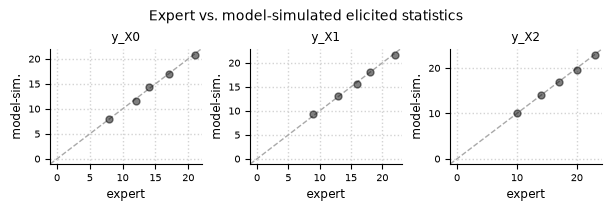

In [7]:
fit.plot.elicits(cols=3, figsize=(6, 2));

## Fit with a gradient optimizer

A gradient cannot pass through a discrete sample.
If you use Adam, set `temp` to use the Gumbel-softmax trick
([Jang et al., 2016](https://doi.org/10.48550/arXiv.1611.01144)).
A small `temp` gives samples near the integers, but noisy gradients.

Adam also needs an initializer.
[Choose an initialization method][choose-an-initialization-method] helps you to pick one.

In [8]:
model_smooth = partial(Model(), design_matrix=design_matrix, total_count=30, temp=1.6)

eliobj_adam = el.Elicit(
    model_smooth,
    targets,
    parameters,
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.05, clipnorm=1.0),
    initializer=el.initializer(
        method="sobol",
        iterations=32,
        distribution=el.initializers.uniform(radius=1.0, mean=0.0),
    ),
    epochs=300,
    verbose=False,
)
fit_adam = eliobj_adam.fit(expert)
fit_adam

W0000 00:00:1794068081.106446  253112 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: op: "Softmax" attr { key: "T" value { type: DT_FLOAT } } inputs { dtype: DT_FLOAT shape { unknown_rank: true } } device { type: "CPU" vendor: "GenuineIntel" model: "101" frequency: 3993 num_cores: 14 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 49152 l2_cache_size: 3145728 l3_cache_size: 18874368 memory_size: 268435456 } outputs { dtype: DT_FLOAT shape { unknown_rank: true } }
W0000 00:00:1794068081.131758  253112 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: op: "Softmax" attr { key: "T" value { type: DT_FLOAT } } inputs { dtype: DT_FLOAT shape { unknown_rank: true } } device { type: "CPU" vendor: "GenuineIntel" model: "101" frequency: 3993 num_cores: 14 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } envir

Method: parametric_prior (300 epochs)
Shown: replication [0] (best)

Hyperparameters:
         estimate
mu0         0.102
mu1         0.195
sigma0      0.397
sigma1      0.226

Priors:
            mean         sd        q05        q95
beta0      0.101      0.399     -0.559      0.758
beta1      0.194      0.226     -0.176      0.563

Fit to expert:
            expert   elicited      error
y_X0[0]       9.25       9.35      0.104
y_X0[1]       12.3       12.3     0.0158
y_X0[2]       14.4       14.6       0.16
y_X0[3]       16.7       16.8     0.0395
y_X0[4]       19.8       19.8     -0.016
y_X1[0]       10.8       10.9     0.0548
y_X1[1]       13.7       13.7     0.0495
y_X1[2]       15.7       15.8     0.0471
y_X1[3]       17.7       17.8     0.0264
y_X1[4]       20.6       20.5     -0.138
y_X2[0]       11.6       11.6  -0.000259
y_X2[1]       14.7       14.7    -0.0134
y_X2[2]         17         17    -0.0271
y_X2[3]       19.1       19.1     0.0198
y_X2[4]       21.9       21.8    -

The oracle simulates its answers with the same model.
Here the answers are therefore smooth too, and they differ from the CMA-ES fit.
The answers of a real expert stay the same for both fits.

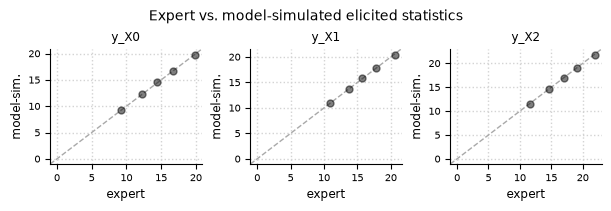

In [9]:
fit_adam.plot.elicits(cols=3, figsize=(6, 2));